In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
files = [
    "../data2/prices_round_2_day_-1.csv",
    "../data2/prices_round_2_day_0.csv",
]

datasets = {}

for file in files:
    df = pd.read_csv(file, sep=";")
    day = df["day"].iloc[0]
    datasets[day] = df


PRODUCT INTARIAN_PEPPER_ROOT | DAY -1
count     9987.000000
mean     11500.124412
std        288.653472
min      10998.000000
25%      11250.500000
50%      11500.000000
75%      11750.000000
max      12001.500000
Name: mid_price, dtype: float64


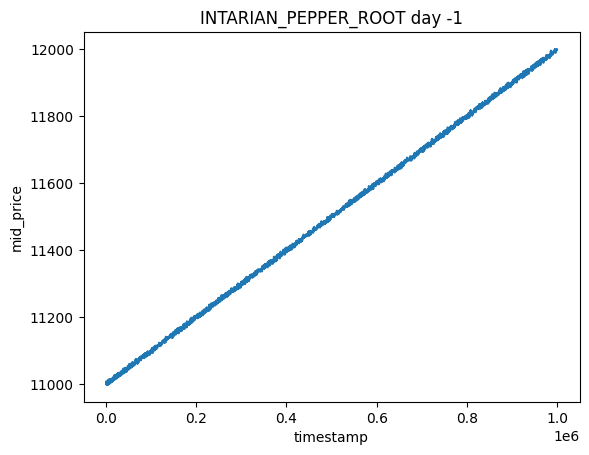


PRODUCT INTARIAN_PEPPER_ROOT | DAY 0
count     9982.000000
mean     12499.866009
std        288.609638
min      11996.000000
25%      12249.500000
50%      12500.000000
75%      12750.000000
max      13008.000000
Name: mid_price, dtype: float64


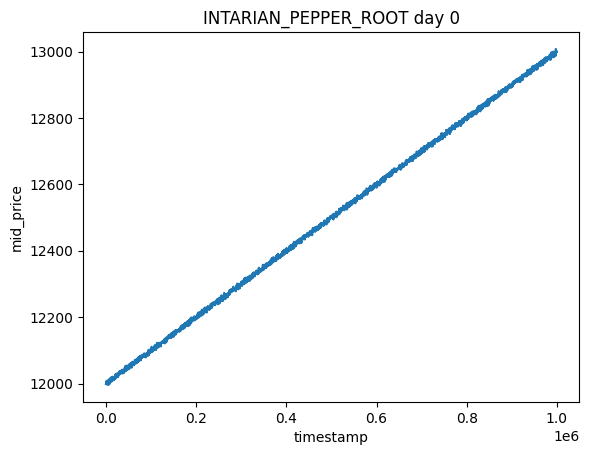

In [3]:
products = ["INTARIAN_PEPPER_ROOT"]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        print(f"\nPRODUCT {product} | DAY {day}")
        print(df_p["mid_price"].describe())

        plt.figure()
        plt.plot(df_p["timestamp"], df_p["mid_price"])
        plt.title(f"{product} day {day}")
        plt.xlabel("timestamp")
        plt.ylabel("mid_price")
        plt.show()

In [4]:
summary_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        summary_rows.append({
            "product": product,
            "day": day,
            "count": df_p["mid_price"].count(),
            "mean": df_p["mid_price"].mean(),
            "median": df_p["mid_price"].median(),
            "std": df_p["mid_price"].std(),
            "min": df_p["mid_price"].min(),
            "max": df_p["mid_price"].max(),
        })

summary_df = pd.DataFrame(summary_rows).sort_values(["product", "day"])
summary_df

,product,day,count,mean,median,std,min,max
0,INTARIAN_PEPPER_ROOT,-1,9987,11500.124412,11500.0,288.653472,10998.0,12001.5
1,INTARIAN_PEPPER_ROOT,0,9982,12499.866009,12500.0,288.609638,11996.0,13008.0


## PEPPER linear-uptrend diagnostics
Use these metrics to quantify trend strength, stability, and how much exploitable noise remains around the trend line.

In [5]:
diag_rows = []
day_series = {}
fit_series = {}
resid_series = {}
segment_rows = []

for day, df in datasets.items():
    df_p = df[df["product"] == "INTARIAN_PEPPER_ROOT"].copy()
    df_p = df_p[df_p["mid_price"] > 0].sort_values("timestamp").copy()
    if len(df_p) < 5:
        continue

    t = df_p["timestamp"].to_numpy(dtype=float)
    y = df_p["mid_price"].to_numpy(dtype=float)

    slope, intercept = np.polyfit(t, y, deg=1)
    y_hat = slope * t + intercept
    resid = y - y_hat

    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    dy = np.diff(y)
    returns = np.diff(np.log(y)) if np.all(y > 0) else np.array([])

    # Segment slope stability: split day into 10 equal index chunks and estimate slope per chunk.
    segment_slopes = []
    for seg_idx in np.array_split(df_p.index.to_numpy(), 10):
        seg = df_p.loc[seg_idx]
        if len(seg) >= 3:
            seg_t = seg["timestamp"].to_numpy(dtype=float)
            seg_y = seg["mid_price"].to_numpy(dtype=float)
            seg_slope = np.polyfit(seg_t, seg_y, deg=1)[0]
            segment_slopes.append(float(seg_slope))

    seg_mean = float(np.mean(segment_slopes)) if segment_slopes else np.nan
    seg_std = float(np.std(segment_slopes)) if segment_slopes else np.nan
    seg_cv = seg_std / abs(seg_mean) if segment_slopes and abs(seg_mean) > 1e-12 else np.nan

    resid_std = float(np.std(resid))
    resid_mad = float(np.median(np.abs(resid - np.median(resid))))
    resid_q95 = float(np.quantile(np.abs(resid), 0.95))

    if resid_std > 1e-12:
        resid_z = resid / resid_std
        outlier_2sigma_rate = float(np.mean(np.abs(resid_z) > 2.0))
        outlier_3sigma_rate = float(np.mean(np.abs(resid_z) > 3.0))
    else:
        outlier_2sigma_rate = np.nan
        outlier_3sigma_rate = np.nan

    diag_rows.append({
        "day": int(day),
        "n": int(len(df_p)),
        "start_price": float(y[0]),
        "end_price": float(y[-1]),
        "day_change": float(y[-1] - y[0]),
        "slope_price_per_ts": float(slope),
        "slope_price_per_10k_ts": float(slope * 10_000),
        "r2_linear": float(r2),
        "rmse_resid": float(np.sqrt(np.mean(resid**2))),
        "resid_std": resid_std,
        "resid_mad": resid_mad,
        "resid_abs_q95": resid_q95,
        "resid_autocorr_lag1": float(pd.Series(resid).autocorr(lag=1)),
        "resid_autocorr_lag5": float(pd.Series(resid).autocorr(lag=5)),
        "positive_step_ratio": float(np.mean(dy > 0)) if len(dy) else np.nan,
        "negative_step_ratio": float(np.mean(dy < 0)) if len(dy) else np.nan,
        "flat_step_ratio": float(np.mean(dy == 0)) if len(dy) else np.nan,
        "step_std": float(np.std(dy)) if len(dy) else np.nan,
        "step_autocorr_lag1": float(pd.Series(dy).autocorr(lag=1)) if len(dy) > 1 else np.nan,
        "logret_mean": float(np.mean(returns)) if len(returns) else np.nan,
        "logret_std": float(np.std(returns)) if len(returns) else np.nan,
        "logret_autocorr_lag1": float(pd.Series(returns).autocorr(lag=1)) if len(returns) > 1 else np.nan,
        "segment_slope_mean": seg_mean,
        "segment_slope_std": seg_std,
        "segment_slope_cv": seg_cv,
        "outlier_2sigma_rate": outlier_2sigma_rate,
        "outlier_3sigma_rate": outlier_3sigma_rate,
    })

    for idx, s in enumerate(segment_slopes):
        segment_rows.append({"day": int(day), "segment": idx, "segment_slope": s})

    day_series[day] = df_p
    fit_series[day] = y_hat
    resid_series[day] = resid

pepper_diag_df = pd.DataFrame(diag_rows).sort_values("day").reset_index(drop=True)
pepper_segment_df = pd.DataFrame(segment_rows)

# Day-to-day shift diagnostics (close->next open gap).
if len(pepper_diag_df) >= 2:
    pepper_diag_df["next_day_open"] = pepper_diag_df["start_price"].shift(-1)
    pepper_diag_df["close_to_next_open_gap"] = pepper_diag_df["next_day_open"] - pepper_diag_df["end_price"]

pepper_diag_df

,day,n,start_price,end_price,day_change,slope_price_per_ts,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,...,logret_mean,logret_std,logret_autocorr_lag1,segment_slope_mean,segment_slope_std,segment_slope_cv,outlier_2sigma_rate,outlier_3sigma_rate,next_day_open,close_to_next_open_gap
0,-1,9987,11001.5,11999.5,998.0,0.001,9.999958,0.999942,2.194477,2.194477,...,0.000009,0.000270,-0.497595,0.001,0.000002,0.001821,0.102533,0.021929,11998.5,-1.0
1,0,9982,11998.5,13000.0,1001.5,0.001,9.999791,0.999933,2.364049,2.364049,...,0.000008,0.000266,-0.489463,0.001,0.000002,0.002236,0.102585,0.023643,NaN,NaN


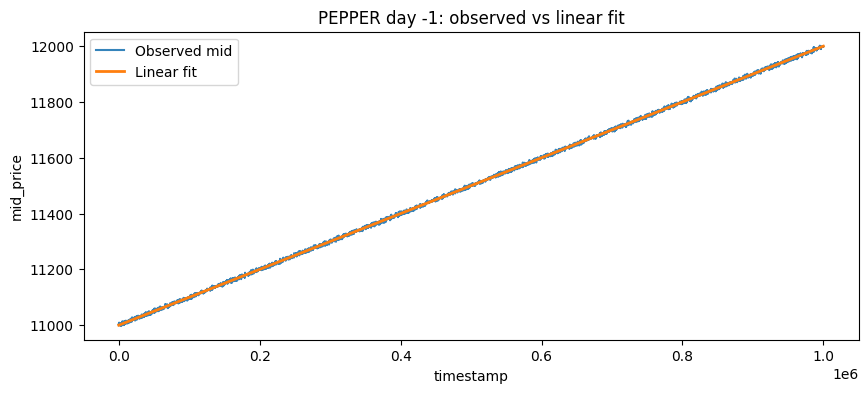

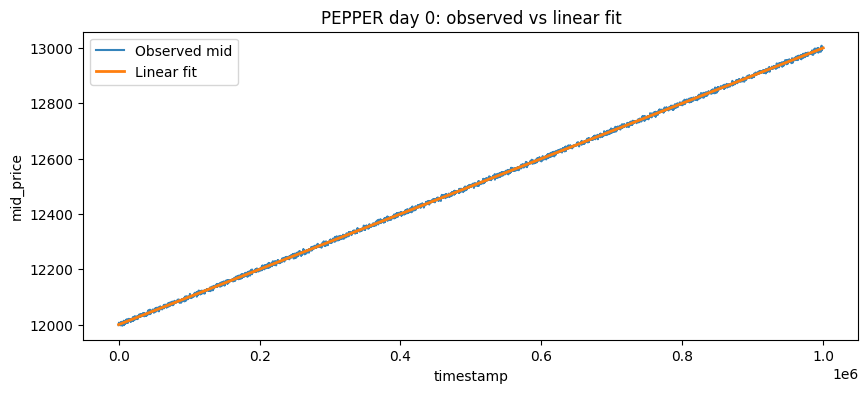

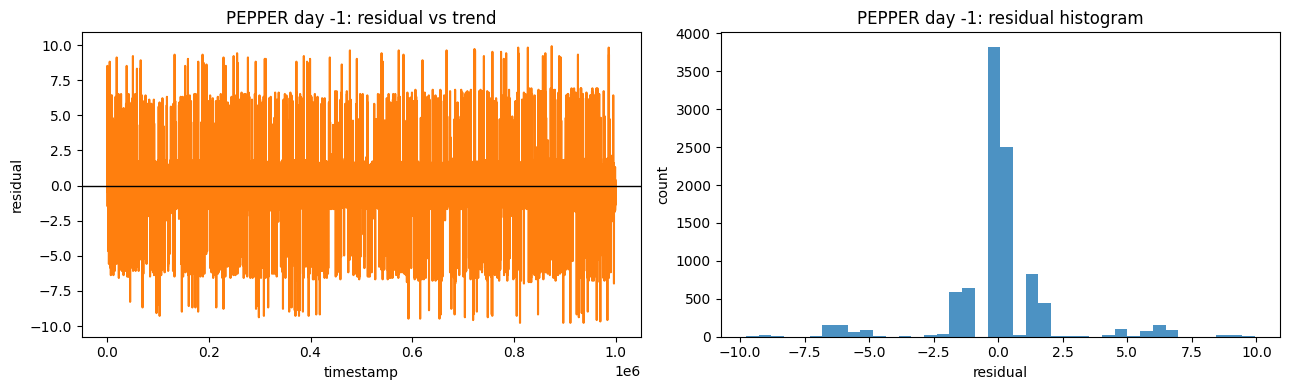

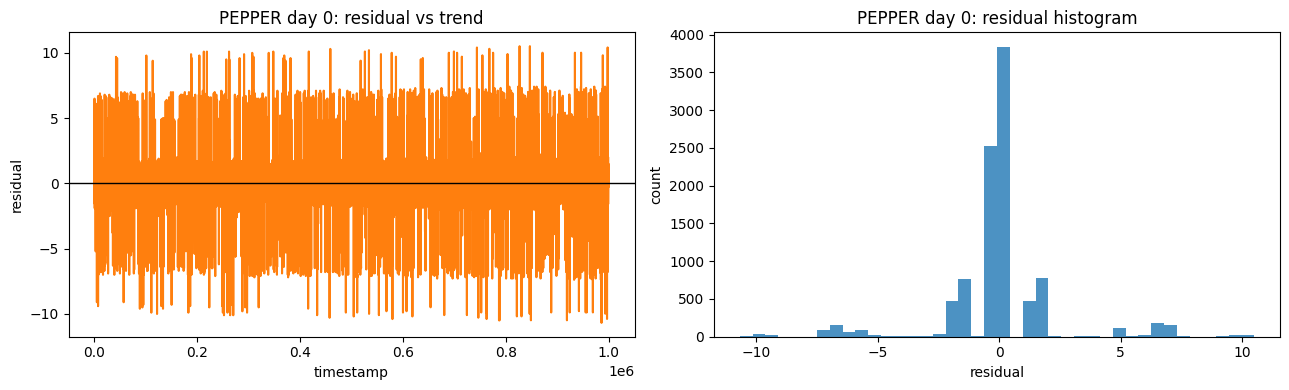

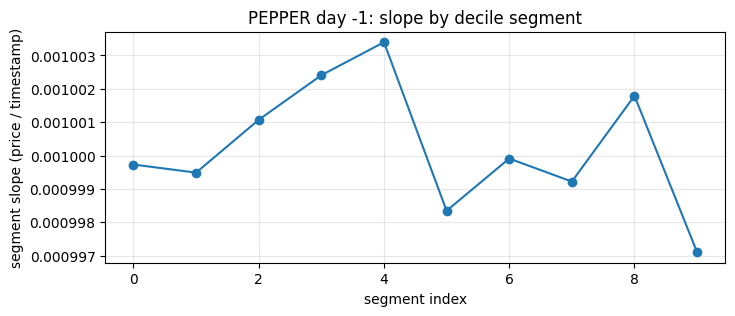

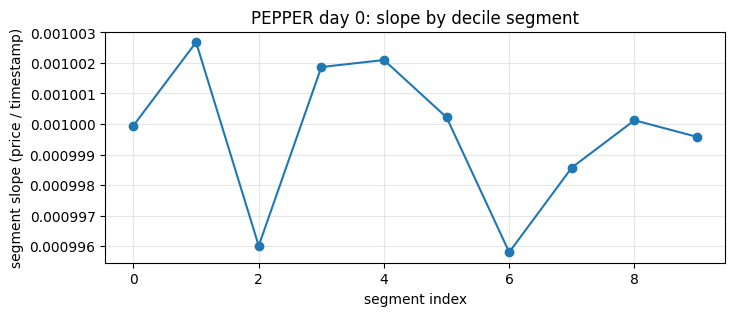

,day,n,start_price,end_price,day_change,slope_price_per_ts,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,...,logret_mean,logret_std,logret_autocorr_lag1,segment_slope_mean,segment_slope_std,segment_slope_cv,outlier_2sigma_rate,outlier_3sigma_rate,next_day_open,close_to_next_open_gap
0,-1,9987,11001.5,11999.5,998.0,0.001,9.999958,0.999942,2.194477,2.194477,...,0.000009,0.000270,-0.497595,0.001,0.000002,0.001821,0.102533,0.021929,11998.5,-1.0
1,0,9982,11998.5,13000.0,1001.5,0.001,9.999791,0.999933,2.364049,2.364049,...,0.000008,0.000266,-0.489463,0.001,0.000002,0.002236,0.102585,0.023643,NaN,NaN


In [6]:
# Plot: observed price and linear fit per day.
for day in sorted(day_series):
    df_p = day_series[day]
    y_hat = fit_series[day]

    plt.figure(figsize=(10, 4))
    plt.plot(df_p["timestamp"], df_p["mid_price"], label="Observed mid", alpha=0.9)
    plt.plot(df_p["timestamp"], y_hat, label="Linear fit", linewidth=2)
    plt.title(f"PEPPER day {day}: observed vs linear fit")
    plt.xlabel("timestamp")
    plt.ylabel("mid_price")
    plt.legend()
    plt.show()

# Plot: residual path and residual distribution summary.
for day in sorted(resid_series):
    df_p = day_series[day]
    resid = resid_series[day]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(df_p["timestamp"], resid, color="tab:orange")
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_title(f"PEPPER day {day}: residual vs trend")
    axes[0].set_xlabel("timestamp")
    axes[0].set_ylabel("residual")

    axes[1].hist(resid, bins=40, color="tab:blue", alpha=0.8)
    axes[1].set_title(f"PEPPER day {day}: residual histogram")
    axes[1].set_xlabel("residual")
    axes[1].set_ylabel("count")

    plt.tight_layout()
    plt.show()

# Plot: segment slope stability across the day.
if not pepper_segment_df.empty:
    for day in sorted(pepper_segment_df["day"].unique()):
        seg = pepper_segment_df[pepper_segment_df["day"] == day]
        plt.figure(figsize=(8, 3))
        plt.plot(seg["segment"], seg["segment_slope"], marker="o")
        plt.title(f"PEPPER day {day}: slope by decile segment")
        plt.xlabel("segment index")
        plt.ylabel("segment slope (price / timestamp)")
        plt.grid(alpha=0.3)
        plt.show()

pepper_diag_df

In [7]:
key_cols = [
    "day",
    "slope_price_per_10k_ts",
    "r2_linear",
    "rmse_resid",
    "resid_std",
    "resid_abs_q95",
    "positive_step_ratio",
    "step_std",
    "segment_slope_cv",
    "outlier_2sigma_rate",
    "close_to_next_open_gap",
]

pepper_diag_df[key_cols].round(6)

,day,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,resid_abs_q95,positive_step_ratio,step_std,segment_slope_cv,outlier_2sigma_rate,close_to_next_open_gap
0,-1,9.999958,0.999942,2.194477,2.194477,6.175745,0.370619,3.107756,0.001821,0.102533,-1.0
1,0,9.999791,0.999933,2.364049,2.364049,6.688676,0.363691,3.316024,0.002236,0.102585,NaN


## PEPPER deeper signal study
Now that linear drift is confirmed, test actionable structure:
- Is there extra edge on pullbacks below trend?
- How stable is local slope over time?
- Is there meaningful curvature beyond a straight line?

In [8]:
horizons = [10, 25, 50, 100]
z_thresholds = [1.0, 1.5, 2.0, 2.5]

event_rows = []
rolling_rows = []
curve_rows = []

for day in sorted(day_series):
    df_p = day_series[day].copy()
    t = df_p["timestamp"].to_numpy(dtype=float)
    y = df_p["mid_price"].to_numpy(dtype=float)
    y_hat = fit_series[day]
    resid = resid_series[day]

    resid_std = float(np.std(resid))
    z = resid / resid_std if resid_std > 1e-12 else np.zeros_like(resid)

    # ---------- Pullback event study ----------
    for thr in z_thresholds:
        hit_idx = np.where(z <= -thr)[0]
        ext_idx = np.where(z >= thr)[0]

        event_row = {
            "day": int(day),
            "z_threshold": thr,
            "n_pullback_events": int(len(hit_idx)),
            "n_extension_events": int(len(ext_idx)),
        }

        for h in horizons:
            valid_pull = hit_idx[hit_idx + h < len(y)]
            valid_ext = ext_idx[ext_idx + h < len(y)]

            if len(valid_pull) > 0:
                pull_rets = (y[valid_pull + h] - y[valid_pull]) / y[valid_pull]
                event_row[f"pull_fwd_ret_{h}"] = float(np.mean(pull_rets))
                event_row[f"pull_pos_rate_{h}"] = float(np.mean(pull_rets > 0))
            else:
                event_row[f"pull_fwd_ret_{h}"] = np.nan
                event_row[f"pull_pos_rate_{h}"] = np.nan

            if len(valid_ext) > 0:
                ext_rets = (y[valid_ext + h] - y[valid_ext]) / y[valid_ext]
                event_row[f"ext_fwd_ret_{h}"] = float(np.mean(ext_rets))
                event_row[f"ext_pos_rate_{h}"] = float(np.mean(ext_rets > 0))
            else:
                event_row[f"ext_fwd_ret_{h}"] = np.nan
                event_row[f"ext_pos_rate_{h}"] = np.nan

        event_rows.append(event_row)

    # ---------- Rolling slope stability ----------
    roll_window = 300
    if len(df_p) > roll_window + 5:
        for i in range(roll_window, len(df_p)):
            t_win = t[i-roll_window:i]
            y_win = y[i-roll_window:i]
            b1, b0 = np.polyfit(t_win, y_win, 1)
            rolling_rows.append({
                "day": int(day),
                "idx": int(i),
                "timestamp": float(t[i]),
                "rolling_slope": float(b1),
            })

    # ---------- Linear vs quadratic fit ----------
    b1, b0 = np.polyfit(t, y, 1)
    y_lin = b1 * t + b0
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    ss_res_lin = float(np.sum((y - y_lin) ** 2))
    r2_lin = 1 - ss_res_lin / ss_tot if ss_tot > 0 else np.nan

    q2, q1, q0 = np.polyfit(t, y, 2)
    y_quad = q2 * t**2 + q1 * t + q0
    ss_res_quad = float(np.sum((y - y_quad) ** 2))
    r2_quad = 1 - ss_res_quad / ss_tot if ss_tot > 0 else np.nan

    curve_rows.append({
        "day": int(day),
        "r2_linear": float(r2_lin),
        "r2_quadratic": float(r2_quad),
        "r2_lift_quad_minus_lin": float(r2_quad - r2_lin),
        "quad_coeff": float(q2),
    })

pepper_event_df = pd.DataFrame(event_rows).sort_values(["day", "z_threshold"]).reset_index(drop=True)
pepper_roll_df = pd.DataFrame(rolling_rows)
pepper_curve_df = pd.DataFrame(curve_rows).sort_values("day").reset_index(drop=True)

pepper_event_df.head(12), pepper_curve_df

(   day  z_threshold  n_pullback_events  n_extension_events  pull_fwd_ret_10  \
 0   -1          1.0                575                 521         0.000627   
 1   -1          1.5                541                 510         0.000649   
 2   -1          2.0                530                 494         0.000653   
 3   -1          2.5                405                 380         0.000691   
 4    0          1.0                554                 552         0.000595   
 5    0          1.5                513                 544         0.000621   
 6    0          2.0                493                 531         0.000631   
 7    0          2.5                381                 406         0.000667   
 
    pull_pos_rate_10  ext_fwd_ret_10  ext_pos_rate_10  pull_fwd_ret_25  \
 0          0.989565       -0.000429         0.044146         0.000749   
 1          0.990758       -0.000436         0.045098         0.000767   
 2          0.990566       -0.000442         0.042510   

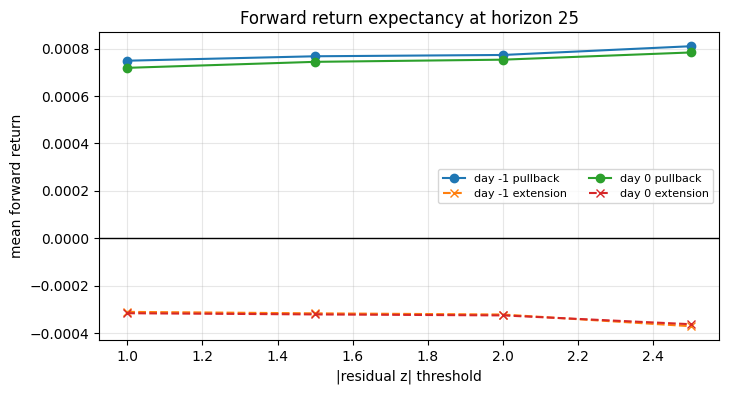

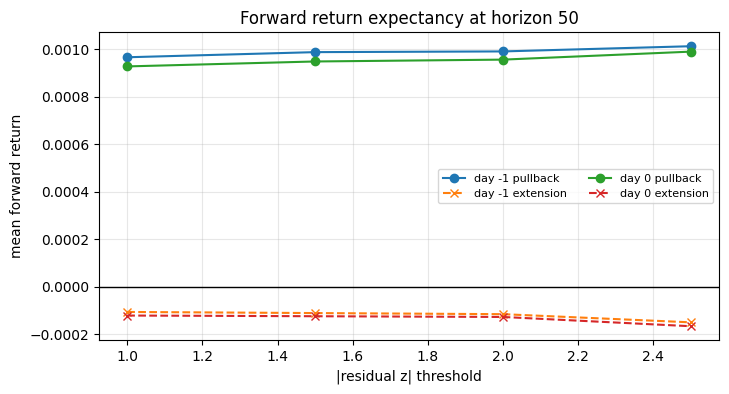

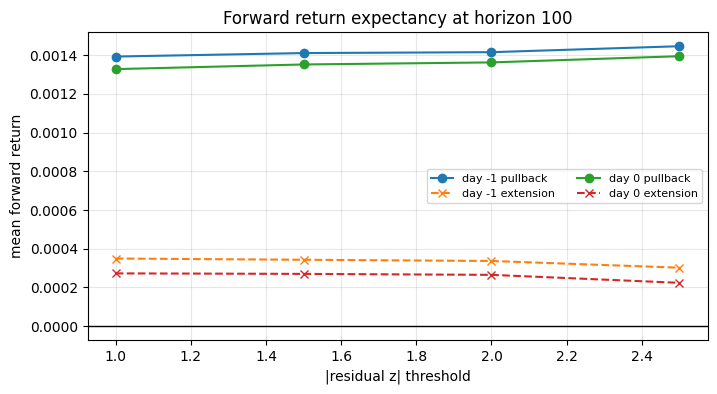

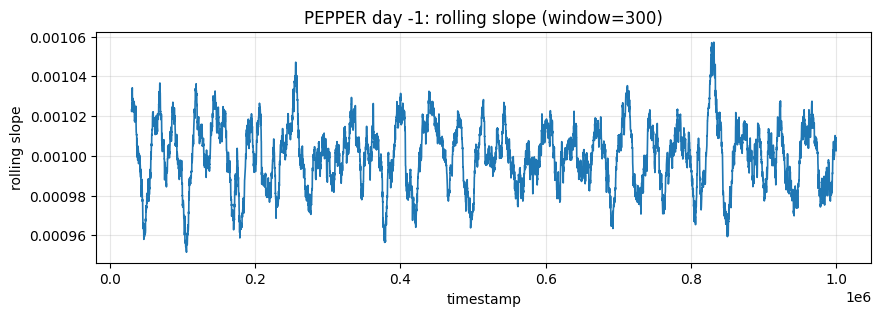

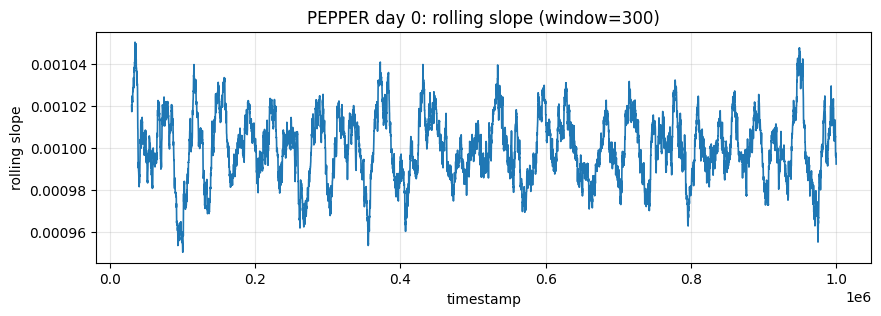

(   day  z_threshold  n_pullback_events  n_extension_events  pull_fwd_ret_50  \
 0   -1          1.0                575                 521         0.000966   
 1   -1          1.5                541                 510         0.000988   
 2   -1          2.0                530                 494         0.000991   
 3   -1          2.5                405                 380         0.001013   
 4    0          1.0                554                 552         0.000928   
 5    0          1.5                513                 544         0.000948   
 6    0          2.0                493                 531         0.000956   
 7    0          2.5                381                 406         0.000990   
 
    pull_pos_rate_50  ext_fwd_ret_50  ext_pos_rate_50  
 0               1.0       -0.000106         0.250000  
 1               1.0       -0.000111         0.235756  
 2               1.0       -0.000116         0.221095  
 3               1.0       -0.000150         0.105541 

In [9]:
# Visualize pullback vs extension event expectancy.
for h in [25, 50, 100]:
    plt.figure(figsize=(8, 4))
    for day in sorted(pepper_event_df["day"].unique()):
        sub = pepper_event_df[pepper_event_df["day"] == day]
        plt.plot(sub["z_threshold"], sub[f"pull_fwd_ret_{h}"], marker="o", label=f"day {day} pullback")
        plt.plot(sub["z_threshold"], sub[f"ext_fwd_ret_{h}"], marker="x", linestyle="--", label=f"day {day} extension")
    plt.axhline(0, color="black", linewidth=1)
    plt.title(f"Forward return expectancy at horizon {h}")
    plt.xlabel("|residual z| threshold")
    plt.ylabel("mean forward return")
    plt.legend(ncol=2, fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

# Visualize rolling slope through time.
if not pepper_roll_df.empty:
    for day in sorted(pepper_roll_df["day"].unique()):
        sub = pepper_roll_df[pepper_roll_df["day"] == day]
        plt.figure(figsize=(10, 3))
        plt.plot(sub["timestamp"], sub["rolling_slope"], linewidth=1.2)
        plt.title(f"PEPPER day {day}: rolling slope (window=300)")
        plt.xlabel("timestamp")
        plt.ylabel("rolling slope")
        plt.grid(alpha=0.3)
        plt.show()

# Compact diagnostic slices for interpretation.
event_focus_cols = [
    "day",
    "z_threshold",
    "n_pullback_events",
    "n_extension_events",
    "pull_fwd_ret_50",
    "pull_pos_rate_50",
    "ext_fwd_ret_50",
    "ext_pos_rate_50",
]

pepper_event_focus = pepper_event_df[event_focus_cols].round(6)
pepper_event_focus, pepper_curve_df.round(8)

In [10]:
# Time-of-day profile averaged across days.
if not pepper_profile_df.empty:
    profile_avg = (
        pepper_profile_df.groupby("time_bucket", as_index=False)
        .agg(
            spread_mean=("spread_mean", "mean"),
            depth_mean=("depth_mean", "mean"),
            abs_ret_mean=("abs_ret_mean", "mean"),
            ret_mean=("ret_mean", "mean"),
        )
        .sort_values("time_bucket")
    )

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    axes = axes.ravel()

    axes[0].plot(profile_avg["time_bucket"], profile_avg["spread_mean"], marker="o")
    axes[0].set_title("Avg spread by intraday decile")
    axes[0].set_xlabel("time bucket")
    axes[0].set_ylabel("spread")
    axes[0].grid(alpha=0.3)

    axes[1].plot(profile_avg["time_bucket"], profile_avg["depth_mean"], marker="o", color="tab:green")
    axes[1].set_title("Avg top-of-book depth by decile")
    axes[1].set_xlabel("time bucket")
    axes[1].set_ylabel("depth")
    axes[1].grid(alpha=0.3)

    axes[2].plot(profile_avg["time_bucket"], profile_avg["abs_ret_mean"] * 1e4, marker="o", color="tab:red")
    axes[2].set_title("Avg absolute return (bps) by decile")
    axes[2].set_xlabel("time bucket")
    axes[2].set_ylabel("abs return (bps)")
    axes[2].grid(alpha=0.3)

    axes[3].plot(profile_avg["time_bucket"], profile_avg["ret_mean"] * 1e4, marker="o", color="tab:purple")
    axes[3].axhline(0, color="black", linewidth=1)
    axes[3].set_title("Avg signed return (bps) by decile")
    axes[3].set_xlabel("time bucket")
    axes[3].set_ylabel("return (bps)")
    axes[3].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# Run-length distribution (persistence of above/below trend states).
if not pepper_runs_df.empty:
    for regime in ["below_trend", "above_trend"]:
        sub = pepper_runs_df[pepper_runs_df["regime"] == regime]
        if len(sub) == 0:
            continue
        plt.figure(figsize=(8, 4))
        plt.hist(sub["run_len"], bins=30, alpha=0.8)
        plt.title(f"Residual run-length distribution: {regime}")
        plt.xlabel("consecutive ticks in regime")
        plt.ylabel("count")
        plt.grid(alpha=0.3)
        plt.show()

display(
    pepper_micro_df.round(6),
    run_summary_df.round(3) if not run_summary_df.empty else run_summary_df,
    profile_avg.round(6) if 'profile_avg' in locals() else pd.DataFrame(),
)

NameError: name 'pepper_profile_df' is not defined

In [ ]:
def estimate_hurst_rs(series, min_chunk=20, max_chunks=8):
    x = np.asarray(series, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) < min_chunk * 4:
        return np.nan

    chunk_sizes = []
    n = len(x)
    for k in range(2, max_chunks + 1):
        m = n // k
        if m >= min_chunk:
            chunk_sizes.append(m)
    chunk_sizes = sorted(set(chunk_sizes))
    if len(chunk_sizes) < 2:
        return np.nan

    rs_vals = []
    ns = []
    for m in chunk_sizes:
        n_chunks = n // m
        if n_chunks < 2:
            continue
        vals = []
        for i in range(n_chunks):
            seg = x[i * m : (i + 1) * m]
            seg = seg - np.mean(seg)
            z = np.cumsum(seg)
            r = np.max(z) - np.min(z)
            s = np.std(seg)
            if s > 1e-12:
                vals.append(r / s)
        if vals:
            rs_vals.append(float(np.mean(vals)))
            ns.append(m)

    if len(rs_vals) < 2:
        return np.nan

    slope, _ = np.polyfit(np.log(ns), np.log(rs_vals), 1)
    return float(slope)

micro_rows = []
profile_rows = []
run_rows = []

for day, df in datasets.items():
    df_p = df[df["product"] == "INTARIAN_PEPPER_ROOT"].copy()
    df_p = df_p[df_p["mid_price"] > 0].sort_values("timestamp").copy()
    if len(df_p) < 20:
        continue

    # Basic microstructure fields.
    df_p["spread"] = np.where(
        (df_p["ask_price_1"] > 0) & (df_p["bid_price_1"] > 0),
        df_p["ask_price_1"] - df_p["bid_price_1"],
        np.nan,
    )
    df_p["depth_top"] = df_p["bid_volume_1"].abs() + df_p["ask_volume_1"].abs()
    df_p["ret_1"] = df_p["mid_price"].pct_change()
    df_p["abs_ret_1"] = df_p["ret_1"].abs()

    t = df_p["timestamp"].to_numpy(dtype=float)
    y = df_p["mid_price"].to_numpy(dtype=float)
    slope, intercept = np.polyfit(t, y, 1)
    y_hat = slope * t + intercept
    resid = y - y_hat

    # Residual sign run lengths: persistence of pullback/extension regimes.
    sign = np.sign(resid)
    sign[np.isclose(sign, 0.0)] = 0
    cur = sign[0]
    run_len = 1
    for s in sign[1:]:
        if s == cur:
            run_len += 1
        else:
            if cur != 0:
                run_rows.append({
                    "day": int(day),
                    "regime": "below_trend" if cur < 0 else "above_trend",
                    "run_len": int(run_len),
                })
            cur = s
            run_len = 1
    if cur != 0:
        run_rows.append({
            "day": int(day),
            "regime": "below_trend" if cur < 0 else "above_trend",
            "run_len": int(run_len),
        })

    # Intraday buckets by timestamp deciles for execution timing insight.
    df_p["time_bucket"] = pd.qcut(df_p["timestamp"], 10, labels=False, duplicates="drop")
    bucket = (
        df_p.groupby("time_bucket", dropna=True)
        .agg(
            spread_mean=("spread", "mean"),
            depth_mean=("depth_top", "mean"),
            abs_ret_mean=("abs_ret_1", "mean"),
            mid_mean=("mid_price", "mean"),
            ret_mean=("ret_1", "mean"),
        )
        .reset_index()
    )
    bucket["day"] = int(day)
    profile_rows.append(bucket)

    hurst = estimate_hurst_rs(df_p["mid_price"].to_numpy())
    micro_rows.append({
        "day": int(day),
        "n": int(len(df_p)),
        "slope_price_per_10k": float(slope * 10000),
        "spread_mean": float(np.nanmean(df_p["spread"])),
        "spread_q90": float(np.nanquantile(df_p["spread"], 0.90)),
        "depth_mean": float(np.nanmean(df_p["depth_top"])),
        "abs_ret_mean_bps": float(np.nanmean(df_p["abs_ret_1"]) * 1e4),
        "abs_ret_q90_bps": float(np.nanquantile(df_p["abs_ret_1"], 0.90) * 1e4),
        "hurst_rs": hurst,
    })

pepper_micro_df = pd.DataFrame(micro_rows).sort_values("day").reset_index(drop=True)
pepper_profile_df = pd.concat(profile_rows, ignore_index=True) if profile_rows else pd.DataFrame()
pepper_runs_df = pd.DataFrame(run_rows)

run_summary_df = (
    pepper_runs_df.groupby(["day", "regime"], as_index=False)
    .agg(
        mean_run_len=("run_len", "mean"),
        median_run_len=("run_len", "median"),
        p90_run_len=("run_len", lambda s: np.quantile(s, 0.9)),
        max_run_len=("run_len", "max"),
        n_runs=("run_len", "count"),
    )
    if not pepper_runs_df.empty
    else pd.DataFrame()
)

pepper_micro_df.round(6), run_summary_df.round(3)

(   day     n  slope_price_per_10k  spread_mean  spread_q90  depth_mean  \
 0   -2  9984            10.000288    11.994792        14.0   23.063585   
 1   -1  9983            10.000758    13.012257        16.0   23.041545   
 2    0  9979            10.000793    14.128715        17.0   23.105155   
 
    abs_ret_mean_bps  abs_ret_q90_bps  hurst_rs  
 0          1.635797         5.395913  1.000998  
 1          1.659444         5.387157  1.001578  
 2          1.615562         5.359189  1.001175  ,
    day       regime  mean_run_len  median_run_len  p90_run_len  max_run_len  \
 0   -2  above_trend         2.465             2.0          4.0           15   
 1   -2  below_trend         2.246             2.0          4.0            9   
 2   -1  above_trend         2.334             2.0          4.0           11   
 3   -1  below_trend         2.351             2.0          4.0           13   
 4    0  above_trend         2.408             2.0          4.0           11   
 5    0  below_tr

## PEPPER microstructure and regime persistence
These diagnostics go beyond trend fit quality and test execution-relevant structure:
- Intraday shape of spread, depth, volatility, and drift
- Residual sign persistence (how long pullbacks/extensions last)
- Hurst-like persistence estimate to classify trending vs mean-reverting behavior

## Execution-adjusted signal scorecard
Convert event-study returns into cost-aware edge estimates using observed PEPPER spread levels.